In [28]:
# importing packages and styling plots
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.cluster import KMeans
import numpy as np
from matplotlib.colors import ListedColormap
import warnings
warnings.filterwarnings("ignore", message="KMeans is known to have a memory leak")
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from matplotlib.transforms import Bbox
from IPython.display import Image, display
from pathlib import Path

import scienceplots 
plt.style.use(["science", "grid"])
plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "legend.fontsize": 9,
    "figure.titlesize": 15,
})
dpi=300

colors_pair = ['#4E79A7', '#E15759']
colors_three = ['#4E79A7', '#E15759', '#59A14F']

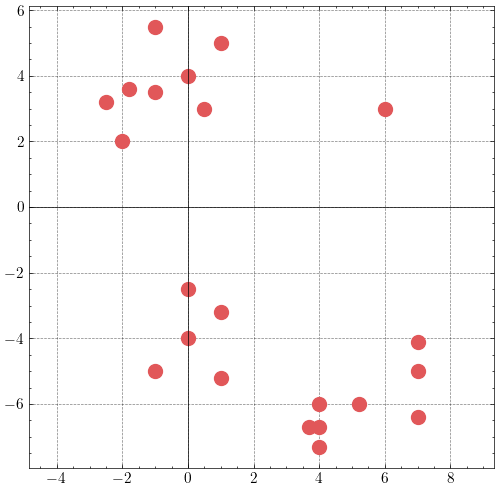

In [29]:
# read (big) dataset and name dimensions
bigd = pd.read_csv('data/big-dataset.csv', header=None)
bigd.columns = ['x', 'y']

# visualize
plt.figure(figsize=(6, 6))

plt.axhline(0, color='black', lw=0.5)
plt.axvline(0, color='black', lw=0.5)
plt.scatter(bigd.x, bigd.y, s=100, color=colors_pair[1])
plt.axis('equal')

plt.savefig('output/dataviz.png', dpi=dpi)
plt.show()

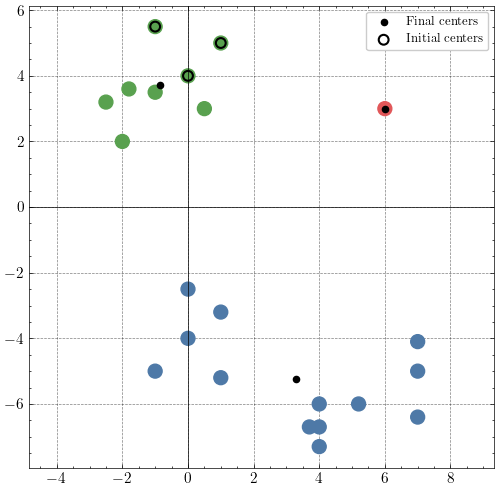

model cluster centers:
 [[ 3.3        -5.23846154]
 [ 6.          3.        ]
 [-0.85        3.725     ]]


In [30]:
# fitting k means with hand-picked initial centers
X = bigd[['x', 'y']].to_numpy()
centers = np.array([[0,4], [1,5], [-1,5.5]])

model = KMeans(n_clusters=3, init=centers, n_init=1)
model.fit(X)

# visualize
plt.figure(figsize=(6, 6))
plt.axhline(0, color='black', lw=0.5)
plt.axvline(0, color='black', lw=0.5)

plt.scatter(bigd.x, bigd.y, c=model.labels_, cmap=ListedColormap(colors_three), s=100)

plt.scatter(*model.cluster_centers_.T, color='black', s=20, label='Final centers')

plt.scatter(*centers.T, facecolors='none', edgecolors='black',
            marker='o', s=50, linewidths=1.5, label='Initial centers')

plt.axis('equal')
plt.legend()
plt.savefig('output/cluster_handpicked_initialization.png', dpi=dpi)
plt.show()

print(f"model cluster centers:\n {model.cluster_centers_}")

In [31]:
def repeated_kmeans(
        repetations=40, init='uniform', random_state=69,
        cluster_colors=ListedColormap(colors_three), savefig_name='output/fig.png',
    ):

    # only used for uniformly drawn initializations
    rng = np.random.default_rng(69)

    # used for both
    results = []

    # 40 random initializations
    for _ in range(repetations):
        centers = X[rng.choice(len(X), size=3, replace=False)].copy()

        if init == 'k-means++':
            model = KMeans(n_clusters=3, init='k-means++', n_init=1)
        elif init == 'uniform':
            model = KMeans(n_clusters=3, init=centers, n_init=1)
        else: 
            Warning('Choose either k-means++ or uniform as initialization method:).')
            
        model.fit(X)

        results.append((model.inertia_, centers, model))

    # select lowest loss
    best_loss = min(r[0] for r in results)
    n_best = sum(np.isclose(r[0], best_loss) for r in results)
    _, centers, model = min(results, key=lambda r: r[0])

    print(f"Lowest k-means loss: {best_loss:.4f}")
    print(f"Minimum encountered: {n_best}/40 times")
    print(f"model cluster centers:\n {model.cluster_centers_}")

    plt.figure(figsize=(5.5, 5.5))
    plt.axhline(0, color='black', lw=0.5)
    plt.axvline(0, color='black', lw=0.5)

    # data points colored by final cluster
    plt.scatter(bigd.x, bigd.y, c=model.labels_, cmap=cluster_colors, s=100)

    # final centers
    plt.scatter(*model.cluster_centers_.T, color='black', s=30,
                label='Final centers')

    plt.axis('equal')
    plt.legend()
    plt.savefig(savefig_name, dpi=dpi)
    plt.show()

Lowest k-means loss: 93.6729
Minimum encountered: 15/40 times
model cluster centers:
 [[-0.08888889  3.64444444]
 [ 5.2375     -6.025     ]
 [ 0.2        -3.98      ]]


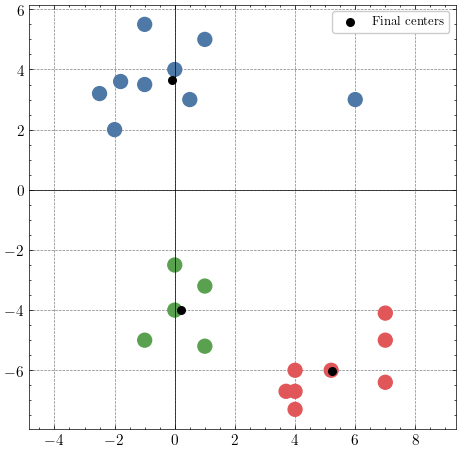

In [32]:
repeated_kmeans(
    repetations=40, init='uniform', cluster_colors=ListedColormap(colors_three),
    savefig_name='output/cluster_uniform_minimizing_kmeansloss.png'
)

Lowest k-means loss: 93.6729
Minimum encountered: 31/40 times
model cluster centers:
 [[ 0.2        -3.98      ]
 [-0.08888889  3.64444444]
 [ 5.2375     -6.025     ]]


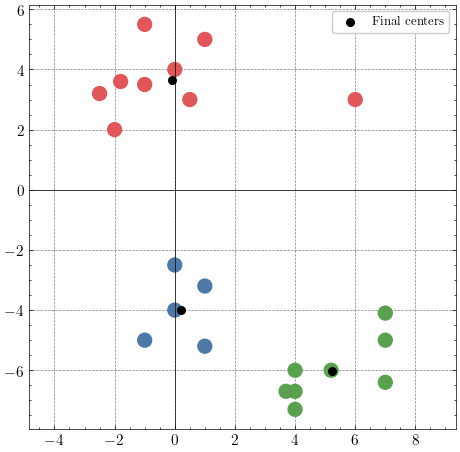

In [33]:
repeated_kmeans(
    repetations=40, init='k-means++', cluster_colors=ListedColormap(colors_three),
    savefig_name='output/cluster_kmeanspp_minimizing_kmeansloss.png'
)

In [34]:
# read in data 
datavis = pd.read_csv('data/vis-dataset.csv', header=None)
datavis.columns = ['x', 'y', 'z']
datavis['h'] = [0]*2000 + [1]*2000
datavis['z'] = datavis['z']

display(datavis.head())
display(datavis.tail())

,x,y,z,h
0,-1.013109,-2.330220,0.070983,0
1,-0.606634,-1.842636,-0.058558,0
2,-1.977246,-2.392645,-0.087200,0
3,-2.030520,-2.437415,0.042715,0
4,-0.745145,-0.849566,0.020319,0


,x,y,z,h
3995,1.450603,-0.944378,0.282363,1
3996,1.477800,-0.945047,-0.224877,1
3997,1.424173,0.445926,0.864289,1
3998,1.590760,-0.010445,1.018304,1
3999,1.587895,-0.703215,0.678885,1


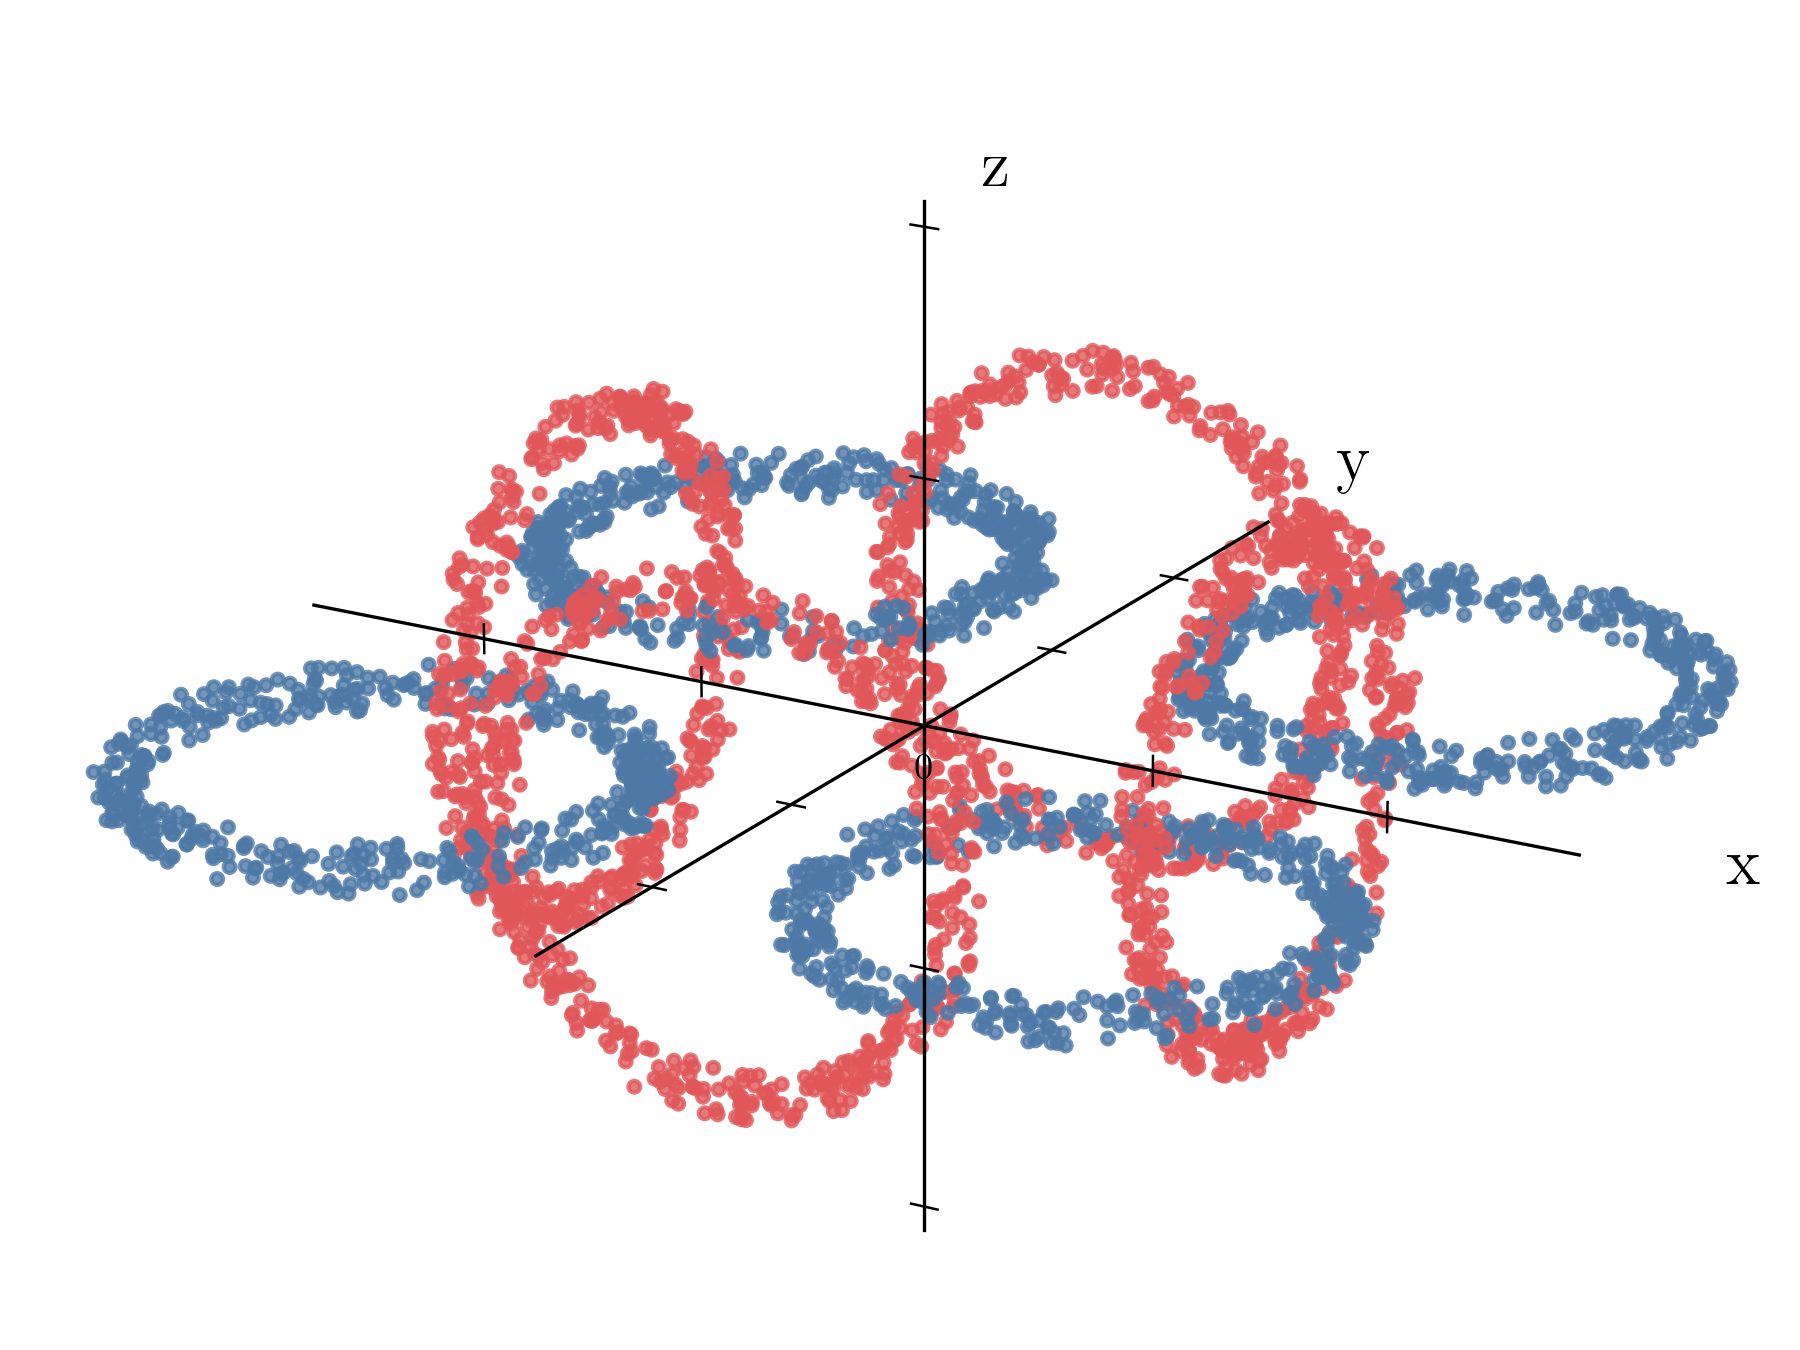

In [35]:
# Settings
ticks = [-2, -1, 0, 1, 2]
dpi = 300
bottom_crop = 1  # Inches removed from the bottom

output_path = Path("output/3dviz.png")
output_path.parent.mkdir(parents=True, exist_ok=True)

# Plotting
fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(111, projection="3d")
fig.subplots_adjust(left=0, right=1, bottom=0, top=1)

ax.scatter(
    datavis.x, datavis.y, datavis.z,
    c=datavis.h,
    cmap=ListedColormap(colors_pair),
    vmin=0, vmax=1,
    s=8,
    depthshade=False,
    alpha=0.8
)

ax.set(
    xlim=(-3.8, 3.8),
    ylim=(-3.8, 3.8),
    zlim=(-3.8, 3.8)
)
ax.set_box_aspect((1, 1, 1), zoom=1.85)
ax.view_init(elev=20, azim=-60)
ax.set_axis_off()

# Centered axes
ax.plot([-2.8, 2.8], [0, 0], [0, 0], "k-", lw=0.8)
ax.plot([0, 0], [-2.8, 2.8], [0, 0], "k-", lw=0.8)
ax.plot([0, 0], [0, 0], [-2.1, 2.1], "k-", lw=0.8)

# Custom ticks
for t in ticks:
    ax.plot([t, t], [0, 0], [-0.06, 0.06], "k-", lw=0.6)
    ax.plot([-0.06, 0.06], [t, t], [0, 0], "k-", lw=0.6)
    ax.plot([-0.06, 0.06], [0, 0], [t, t], "k-", lw=0.6)

ax.text(0, 0, -0.22, "0", ha="center", fontsize=9)

# Axis labels
ax.text(3.4, 0, 0, "x", fontsize=16)
ax.text(0, 3.4, 0, "y", fontsize=16)
ax.text(0.25, 0, 2.2, "z", fontsize=16)

# Save with the bottom whitespace cropped
width, height = fig.get_size_inches()
crop = Bbox.from_extents(0, bottom_crop, width, height-0.5)

fig.savefig(output_path, dpi=dpi, bbox_inches=crop)

# Display the cropped image
plt.close(fig)
display(Image(filename=str(output_path), width=600))

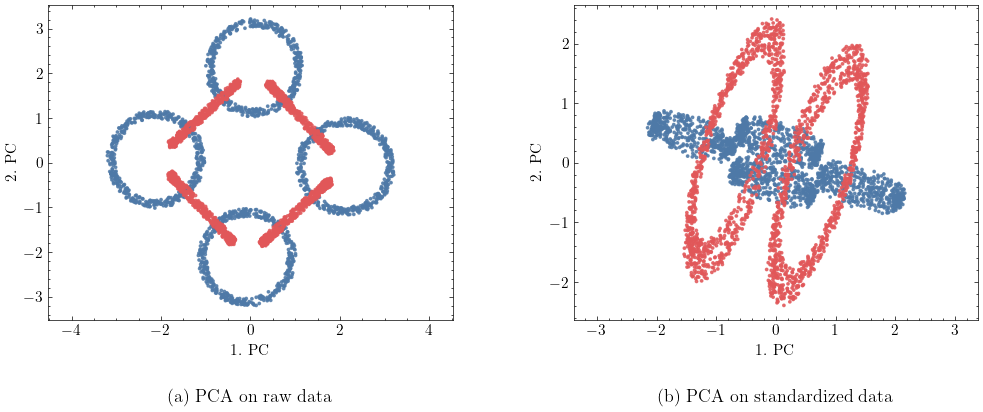


Raw data
Explained variance ratio: [0.48237505 0.4608992 ]
Principal component directions:
 [[-0.67833657  0.73474546  0.00293509]
 [ 0.73475114  0.67833377  0.0020144 ]]

Standardized data
Explained variance ratio: [0.34165239 0.33298618]
Principal component directions:
 [[-0.65324941  0.69883345  0.29137092]
 [ 0.36574971 -0.04569046  0.92959106]]


In [36]:
cols_raw = ["x", "y", "z"]
cols_standardised = ["x_stand", "y_stand", "z_stand"]

datavis[cols_standardised] = StandardScaler().fit_transform(datavis[cols_raw])

# Fit separate PCA models
pca_raw = PCA(n_components=2)
X_pca = pca_raw.fit_transform(datavis[cols_raw])

pca_scaled = PCA(n_components=2)
X_pca_0mean1var = pca_scaled.fit_transform(datavis[cols_standardised])

# Side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, scores, title in zip(
    axes,
    [X_pca, X_pca_0mean1var],
    ["(a) PCA on raw data", "(b) PCA on standardized data"]
):
    ax.scatter(
        scores[:, 0], scores[:, 1],
        c=datavis.h,
        cmap=ListedColormap(colors_pair),
        vmin=0, vmax=1,
        s=3, alpha=0.8
    )

    ax.set_xlabel("1. PC")
    ax.set_ylabel("2. PC")
    ax.set_aspect("equal", adjustable="datalim")
    ax.grid(False)

    # Title underneath the plot
    ax.text(
        0.5, -0.22, title,
        transform=ax.transAxes,
        ha="center", va="top",
        fontsize=13
    )

fig.subplots_adjust(bottom=0.25, wspace=0.3)
plt.savefig('output/PCA.png',dpi=dpi)
plt.show()

for label, model in [("Raw data", pca_raw), ("Standardized data", pca_scaled)]:
    print(f"\n{label}")
    print("Explained variance ratio:", model.explained_variance_ratio_)
    print("Principal component directions:\n", model.components_)

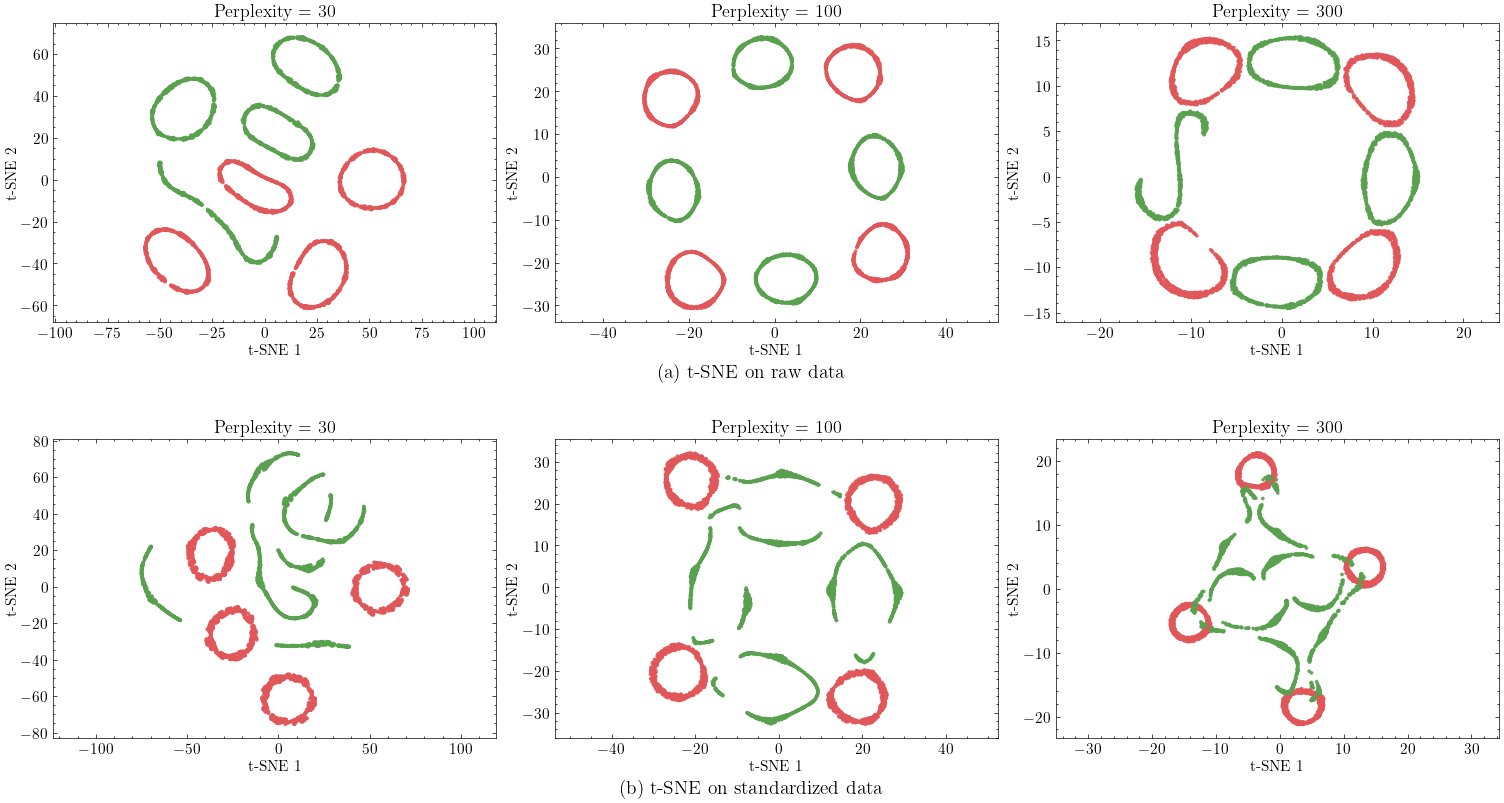

In [37]:
X_raw = datavis[cols_raw].to_numpy()
X_standardised = datavis[cols_standardised].to_numpy()

# # Same random initialization for all six plots
# rng = np.random.default_rng(69)
# init = rng.normal(0, 1e-4, size=(len(X_raw), 2))

fig = plt.figure(figsize=(15, 8), layout="constrained")

# Small gaps; automatically leave room for labels
fig.get_layout_engine().set(
    w_pad=0.03,
    h_pad=0.03,
    wspace=0.02,
    hspace=0.02
)

row_figures = fig.subfigures(2, 1, hspace=0.08)

for row_fig, X, caption in zip(
    row_figures,
    [X_raw, X_standardised],
    ["(a) t-SNE on raw data", "(b) t-SNE on standardized data"]
):
    axes = row_fig.subplots(1, 3)

    for ax, perplexity in zip(axes, [30, 100, 300]):
        tsne = TSNE(
            n_components=2,
            perplexity=perplexity,
            learning_rate='auto',
            init='random',
            random_state=69
        )

        X_tsne = tsne.fit_transform(X)

        ax.scatter(
            X_tsne[:, 0], X_tsne[:, 1],
            c=datavis.h,
            cmap=ListedColormap(colors_three[1:]),
            vmin=0, vmax=1,
            s=3, alpha=0.8
        )

        ax.set_title(f"Perplexity = {perplexity}", pad=5)
        ax.set_xlabel("t-SNE 1", labelpad=2)
        ax.set_ylabel("t-SNE 2", labelpad=2)
        ax.set_aspect("equal", adjustable="datalim")
        ax.grid(False)

    # Caption immediately underneath this row
    row_fig.supxlabel(caption, fontsize=14)

plt.savefig('output/tSNE.png', dpi=dpi)
plt.show()

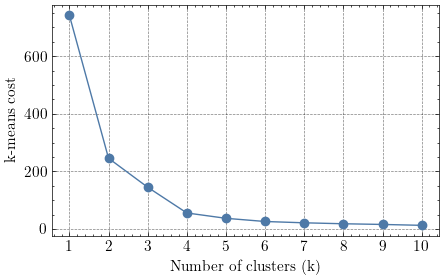

In [38]:
# k-means cost for different numbers of clusters (for data.csv / data.txt)
data = pd.read_csv('data/data.csv', header=None)
data = data.to_numpy()

ks = range(1, 11)
losses = []

for k in ks:
    model = KMeans(n_clusters=k, init='k-means++',
                   n_init=40, random_state=69)
    model.fit(data)
    losses.append(model.inertia_)

# visualize
plt.figure(figsize=(5, 3))
plt.plot(ks, losses, 'o-', color=colors_three[0])
plt.xlabel('Number of clusters (k)')
plt.ylabel('k-means cost')
plt.xticks(ks)

plt.savefig('output/elbow_plot.png', dpi=dpi)
plt.show()